# 04 - Modeling

Predict `compressive_strength` (MPa) from mix composition and curing age.

1. Setup  2. Preprocessing  3. Baseline models  4. Advanced models  5. Cross-validation  6. Hyperparameter tuning  7. Final evaluation  8. Save

In [1]:
import json
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import ks_2samp
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import (GridSearchCV, KFold, ParameterGrid, RandomizedSearchCV,
                                     cross_validate, train_test_split)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor

SEED = 42
DATA_PATH = Path('..') / 'Data' / 'concrete_data.csv'
MODEL_DIR = Path('models')
MODEL_DIR.mkdir(exist_ok=True)

pd.set_option('display.float_format', '{:,.3f}'.format)

COLOR, GREY = '#2a78d6', '#a3a29c'
INK, INK_2, GRID, SURFACE = '#0b0b0b', '#52514e', '#e1e0d9', '#fcfcfb'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK_2, 'axes.titlecolor': INK,
    'xtick.color': INK_2, 'ytick.color': INK_2,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'font.size': 10,
})

---
## 1. Setup

The data is loaded from `Data/concrete_data.csv`, and `slag` and `strength` are renamed to `blast_furnace_slag` and `compressive_strength`. The saved model's feature names then match what the web app (`Application/`) expects. The 25 exact duplicate rows found in EDA are dropped **before** splitting, so an identical row can't appear in both train and test.

In [2]:
df = pd.read_csv(DATA_PATH)
df = df.rename(columns={'slag': 'blast_furnace_slag', 'strength': 'compressive_strength'})
n_raw = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f'Loaded {n_raw} rows, dropped {n_raw - len(df)} duplicates, {len(df)} remain')

TARGET = 'compressive_strength'
FEATURES = ['cement', 'blast_furnace_slag', 'fly_ash', 'water', 'superplasticizer',
            'coarse_aggregate', 'fine_aggregate', 'age']
X, y = df[FEATURES], df[TARGET]
X.shape, y.shape

Loaded 1030 rows, dropped 25 duplicates, 1005 remain


((1005, 8), (1005,))

### 1.1 Stratified train/test split (80:20)

A plain random split can leave some ages (and strength levels) over- or under-represented in the test set. So the split is **stratified on age group × strength quintile**:

- age groups follow the EDA: early (1–7 d), standard (14–28 d), mid (56–100 d), late (120–365 d)
- strength is cut into 5 quantile bins

This keeps both the age mix and the target distribution the same in train and test. Strata too small to split (< 5 rows) fall back to their age group alone.

In [3]:
age_group = pd.cut(df['age'], bins=[0, 7, 28, 100, 365],
                   labels=['early_1-7', 'standard_14-28', 'mid_56-100', 'late_120-365'])
strength_q = pd.qcut(y, q=5, labels=[f'Q{i}' for i in range(1, 6)])
strata = age_group.astype(str) + '|' + strength_q.astype(str)

counts = strata.value_counts()
rare = strata.map(counts) < 5
strata[rare] = age_group[rare].astype(str)
print(f'{strata.nunique()} strata, {rare.sum()} rows moved to age-only strata')

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=strata)
print(f'Train: {X_train.shape}, Test: {X_test.shape}')

18 strata, 0 rows moved to age-only strata
Train: (804, 8), Test: (201, 8)


### 1.2 Check that the split is balanced

The proportion of each age group should match in train and test. For every column, the means should be close, and the two-sample Kolmogorov–Smirnov test (checks whether two samples come from the same distribution) should **not** reject (p > 0.05).

In [4]:
age_share = pd.DataFrame({
    'train_%': age_group.loc[X_train.index].value_counts(normalize=True) * 100,
    'test_%': age_group.loc[X_test.index].value_counts(normalize=True) * 100,
}).sort_index()
display(age_share)

train_full, test_full = df.loc[X_train.index], df.loc[X_test.index]
balance = pd.DataFrame({
    'train_mean': train_full.mean(), 'test_mean': test_full.mean(),
    'train_std': train_full.std(), 'test_std': test_full.std(),
    'ks_pvalue': [ks_2samp(train_full[c], test_full[c]).pvalue for c in df.columns],
})
balance['balanced (p>0.05)'] = balance['ks_pvalue'] > 0.05
balance

,train_%,test_%
age,,
early_1-7,25.124,25.373
standard_14-28,47.886,47.761
mid_56-100,20.771,20.896
late_120-365,6.219,5.970


,train_mean,test_mean,train_std,test_std,ks_pvalue,balanced (p>0.05)
cement,280.928,269.432,104.226,104.575,0.236,True
blast_furnace_slag,71.574,73.918,87.002,82.944,0.656,True
fly_ash,55.431,55.950,64.421,63.502,0.709,True
water,182.704,179.557,20.989,22.573,0.136,True
superplasticizer,5.929,6.441,5.847,6.199,0.525,True
coarse_aggregate,975.062,971.636,77.750,77.026,0.603,True
fine_aggregate,769.293,786.263,81.661,73.459,0.146,True
age,46.284,44.149,64.448,60.923,1.000,True
compressive_strength,35.304,35.036,16.310,16.221,0.876,True


> **Caveat: the same mix at several ages.** Many mixes appear several times, tested at different ages. A row-level split, even a stratified one, can put the same mix (at different ages) in both train and test. So test scores here show how well the model fills in **new ages for known mixes**, and may be optimistic for completely **new mix designs**. A grouped split by mix would measure that harder case.

---
## 2. Preprocessing

The `StandardScaler` is **fit on the training set only**, then used to transform both sets. That way the test set's mean and std don't leak into training. The target is not scaled.

Scaling matters for Linear/Ridge/Lasso (fair regularisation), KNN and SVR (distance-based). Trees don't need it, but it does no harm, so every model uses the same inputs.

In [5]:
scaler = StandardScaler().fit(X_train)
X_train_s = pd.DataFrame(scaler.transform(X_train), columns=FEATURES, index=X_train.index)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=FEATURES, index=X_test.index)

pd.DataFrame({'train_mean': X_train_s.mean(), 'train_std': X_train_s.std(ddof=0),
              'test_mean': X_test_s.mean(), 'test_std': X_test_s.std(ddof=0)})

,train_mean,train_std,test_mean,test_std
cement,0.000,1.000,-0.110,1.001
blast_furnace_slag,0.000,1.000,0.027,0.952
fly_ash,0.000,1.000,0.008,0.984
water,-0.000,1.000,-0.150,1.073
superplasticizer,-0.000,1.000,0.087,1.058
coarse_aggregate,-0.000,1.000,-0.044,0.989
fine_aggregate,0.000,1.000,0.208,0.898
age,0.000,1.000,-0.033,0.944


Train columns now have mean 0 and std 1 exactly. Test columns are close to that but not exact, which is expected because the scaler never saw them.

---
## 3. Baseline models

Linear models with default hyperparameters (Ridge `alpha=1`, Lasso `alpha=1`).

In [6]:
def evaluate(name, model, Xtr, ytr, Xte, yte, group):
    t0 = time.perf_counter()
    model.fit(Xtr, ytr)
    fit_s = time.perf_counter() - t0
    p_tr, p_te = model.predict(Xtr), model.predict(Xte)
    return {
        'model': name, 'group': group,
        'train_R2': r2_score(ytr, p_tr), 'test_R2': r2_score(yte, p_te),
        'train_RMSE': root_mean_squared_error(ytr, p_tr), 'test_RMSE': root_mean_squared_error(yte, p_te),
        'train_MAE': mean_absolute_error(ytr, p_tr), 'test_MAE': mean_absolute_error(yte, p_te),
        'fit_s': fit_s,
    }


def results_table(rows):
    t = pd.DataFrame(rows).set_index('model')
    t['R2_gap'] = t['train_R2'] - t['test_R2']   # large gap = overfitting
    return t


BASELINES = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(alpha=1.0),
    'Lasso': Lasso(alpha=1.0, max_iter=10_000),
}
baseline_rows = [evaluate(n, m, X_train_s, y_train, X_test_s, y_test, 'baseline') for n, m in BASELINES.items()]
results_table(baseline_rows)

,group,train_R2,test_R2,train_RMSE,test_RMSE,train_MAE,test_MAE,fit_s,R2_gap
model,,,,,,,,,
Linear Regression,baseline,0.605,0.595,10.250,10.304,8.118,8.338,0.014,0.010
Ridge,baseline,0.605,0.594,10.251,10.311,8.122,8.351,0.009,0.011
Lasso,baseline,0.554,0.542,10.882,10.953,8.736,9.106,0.004,0.013


In [7]:
coefs = pd.DataFrame({n: m.coef_ for n, m in BASELINES.items()}, index=FEATURES)
print('Coefficients (MPa change per 1 std increase in the feature):')
coefs

Coefficients (MPa change per 1 std increase in the feature):


,Linear Regression,Ridge,Lasso
cement,11.860,11.659,7.246
blast_furnace_slag,7.852,7.656,3.101
fly_ash,5.099,4.923,0.081
water,-4.097,-4.221,-3.089
superplasticizer,1.095,1.102,3.038
coarse_aggregate,0.428,0.300,-0.000
fine_aggregate,0.779,0.606,-0.584
age,7.002,6.983,5.314


Linear models explain only about 60% of the variance. Strength rises steeply with age early on and then levels off, and ingredients interact (w/c, binder). A straight line can't capture either, which is why the non-linear models below exist.

---
## 4. Advanced models

Non-linear models with library defaults (plus a fixed `random_state`). They are tuned in section 6.

In [8]:
ADVANCED = {
    'Decision Tree': DecisionTreeRegressor(random_state=SEED),
    'Random Forest': RandomForestRegressor(random_state=SEED, n_jobs=1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=SEED),
    'XGBoost': XGBRegressor(random_state=SEED, n_jobs=1, verbosity=0),
    'KNN': KNeighborsRegressor(),
    'SVR (RBF)': SVR(kernel='rbf'),
}
advanced_rows = [evaluate(n, m, X_train_s, y_train, X_test_s, y_test, 'advanced') for n, m in ADVANCED.items()]
holdout = results_table(baseline_rows + advanced_rows)
holdout.sort_values('test_R2', ascending=False)

,group,train_R2,test_R2,train_RMSE,test_RMSE,train_MAE,test_MAE,fit_s,R2_gap
model,,,,,,,,,
XGBoost,advanced,0.996,0.939,0.995,4.009,0.390,2.673,0.208,0.058
Random Forest,advanced,0.984,0.915,2.062,4.714,1.353,3.431,0.511,0.069
Gradient Boosting,advanced,0.944,0.910,3.841,4.849,2.931,3.705,0.223,0.034
Decision Tree,advanced,0.997,0.843,0.847,6.411,0.061,4.343,0.009,0.154
KNN,advanced,0.810,0.701,7.096,8.846,5.457,6.966,0.005,0.109
SVR (RBF),advanced,0.641,0.605,9.768,10.169,7.424,8.070,0.031,0.036
Linear Regression,baseline,0.605,0.595,10.250,10.304,8.118,8.338,0.014,0.010
Ridge,baseline,0.605,0.594,10.251,10.311,8.122,8.351,0.009,0.011
Lasso,baseline,0.554,0.542,10.882,10.953,8.736,9.106,0.004,0.013


- **Decision Tree** fits the training set almost perfectly but drops on test, a classic case of overfitting (look at `R2_gap`).
- **SVR** with default `C=1` is heavily regularised for a target in the tens of MPa, so it underfits. Tuning will fix that if SVR reaches the top 2.
- The tree ensembles (XGBoost, Random Forest, Gradient Boosting) are clearly ahead of everything else.

---
## 5. Cross-validation

5-fold CV on the **training set only** (the test set stays held out). Each model is wrapped in a `Pipeline(StandardScaler → model)`, so the scaler is refit inside every fold and the validation fold never leaks into scaling.

In [9]:
ALL_MODELS = {**BASELINES, **ADVANCED}
CV = KFold(n_splits=5, shuffle=True, random_state=SEED)


def make_pipe(model):
    return Pipeline([('scaler', StandardScaler()), ('model', model)])


cv_rows = []
for name, model in ALL_MODELS.items():
    s = cross_validate(make_pipe(model), X_train, y_train, cv=CV, n_jobs=-1,
                       scoring={'r2': 'r2', 'rmse': 'neg_root_mean_squared_error'})
    cv_rows.append({'model': name, 'CV_R2_mean': s['test_r2'].mean(), 'CV_R2_std': s['test_r2'].std(),
                    'CV_RMSE_mean': -s['test_rmse'].mean(),
                    'fold_R2': np.round(s['test_r2'], 3).tolist()})

cv_table = (pd.DataFrame(cv_rows).set_index('model')
            .join(holdout[['group', 'test_R2', 'test_RMSE']])
            .sort_values('CV_R2_mean', ascending=False))
cv_table

,CV_R2_mean,CV_R2_std,CV_RMSE_mean,fold_R2,group,test_R2,test_RMSE
model,,,,,,,
XGBoost,0.912,0.018,4.782,"[0.903, 0.945, 0.898, 0.918, 0.897]",advanced,0.939,4.009
Random Forest,0.895,0.024,5.213,"[0.877, 0.942, 0.879, 0.893, 0.884]",advanced,0.915,4.714
Gradient Boosting,0.888,0.019,5.418,"[0.868, 0.918, 0.873, 0.9, 0.881]",advanced,0.910,4.849
Decision Tree,0.818,0.028,6.893,"[0.819, 0.865, 0.79, 0.83, 0.787]",advanced,0.843,6.411
KNN,0.681,0.023,9.149,"[0.667, 0.705, 0.694, 0.695, 0.643]",advanced,0.701,8.846
Ridge,0.589,0.026,10.395,"[0.596, 0.596, 0.626, 0.546, 0.58]",baseline,0.594,10.311
Linear Regression,0.589,0.027,10.394,"[0.596, 0.597, 0.627, 0.545, 0.579]",baseline,0.595,10.304
SVR (RBF),0.580,0.009,10.518,"[0.597, 0.576, 0.577, 0.568, 0.582]",advanced,0.605,10.169
Lasso,0.540,0.023,11.003,"[0.571, 0.536, 0.557, 0.503, 0.533]",baseline,0.542,10.953


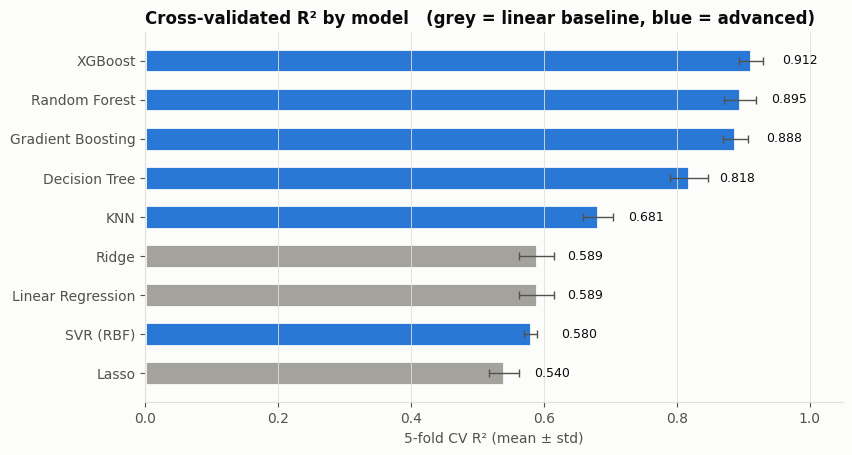

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.8))
t = cv_table.iloc[::-1]
colors = [COLOR if g == 'advanced' else GREY for g in t['group']]
ax.barh(t.index, t['CV_R2_mean'], xerr=t['CV_R2_std'], color=colors, height=0.6,
        edgecolor=SURFACE, linewidth=2, error_kw={'ecolor': INK_2, 'elinewidth': 1, 'capsize': 3})
for i, v in enumerate(t['CV_R2_mean']):
    ax.annotate(f'{v:.3f}', (max(v, 0), i), xytext=(22, 0), textcoords='offset points', va='center', fontsize=9, color=INK)
ax.set_xlim(0, 1.05)
ax.set_xlabel('5-fold CV R² (mean ± std)')
ax.set_title('Cross-validated R² by model   (grey = linear baseline, blue = advanced)', loc='left')
ax.grid(axis='y', visible=False)
plt.show()

---
## 6. Hyperparameter tuning

The **top 2 models by CV R²** are tuned on the training set with 5-fold CV. Search spaces are defined for every model, so whichever two come out on top can be tuned without edits. Small spaces use `GridSearchCV` (exhaustive). Large ones use `RandomizedSearchCV` with 60 samples.

In [11]:
SEARCH_SPACES = {
    'Linear Regression': {},
    'Ridge': {'model__alpha': np.logspace(-3, 3, 13).tolist()},
    'Lasso': {'model__alpha': np.logspace(-4, 1, 11).tolist()},
    'Decision Tree': {'model__max_depth': [None, 4, 6, 8, 10, 15, 20],
                      'model__min_samples_split': [2, 5, 10, 20],
                      'model__min_samples_leaf': [1, 2, 4, 8]},
    'Random Forest': {'model__n_estimators': [200, 400, 600],
                      'model__max_depth': [None, 10, 20, 30],
                      'model__min_samples_split': [2, 5, 10],
                      'model__min_samples_leaf': [1, 2, 4],
                      'model__max_features': [1.0, 'sqrt', 0.5]},
    'Gradient Boosting': {'model__n_estimators': [200, 400, 800, 1200],
                          'model__learning_rate': [0.02, 0.05, 0.1, 0.2],
                          'model__max_depth': [2, 3, 4, 5, 6],
                          'model__subsample': [0.7, 0.85, 1.0],
                          'model__min_samples_leaf': [1, 3, 5]},
    'XGBoost': {'model__n_estimators': [300, 600, 1000, 1500],
                'model__learning_rate': [0.02, 0.05, 0.1],
                'model__max_depth': [3, 4, 5, 6, 8],
                'model__subsample': [0.7, 0.85, 1.0],
                'model__colsample_bytree': [0.6, 0.8, 1.0],
                'model__min_child_weight': [1, 3, 5],
                'model__reg_lambda': [0.5, 1, 5]},
    'KNN': {'model__n_neighbors': list(range(2, 21)),
            'model__weights': ['uniform', 'distance'],
            'model__p': [1, 2]},
    'SVR (RBF)': {'model__C': [1, 10, 100, 300, 1000],
                  'model__gamma': ['scale', 0.01, 0.05, 0.1, 0.3, 1.0],
                  'model__epsilon': [0.05, 0.1, 0.5, 1.0]},
}
MAX_GRID, N_ITER = 100, 60

top2 = cv_table.index[:2].tolist()
print('Tuning:', top2)

Tuning: ['XGBoost', 'Random Forest']


In [12]:
searches = {}
for name in top2:
    space = SEARCH_SPACES[name]
    pipe = make_pipe(ALL_MODELS[name])
    n_combos = len(ParameterGrid(space)) if space else 1
    if n_combos <= MAX_GRID:
        search = GridSearchCV(pipe, space or {}, cv=CV, scoring='r2', n_jobs=-1)
    else:
        search = RandomizedSearchCV(pipe, space, n_iter=N_ITER, cv=CV, scoring='r2',
                                    n_jobs=-1, random_state=SEED)
    t0 = time.perf_counter()
    search.fit(X_train, y_train)
    searches[name] = search
    print(f'{name}: {type(search).__name__} over {min(n_combos, N_ITER) if n_combos > MAX_GRID else n_combos} '
          f'of {n_combos} combos in {time.perf_counter() - t0:.0f}s, best CV R2 = {search.best_score_:.4f}')
    print('   best params:', {k.replace('model__', ''): v for k, v in search.best_params_.items()})

XGBoost: RandomizedSearchCV over 60 of 4860 combos in 74s, best CV R2 = 0.9252
   best params: {'subsample': 0.85, 'reg_lambda': 0.5, 'n_estimators': 600, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.1, 'colsample_bytree': 0.6}


Random Forest: RandomizedSearchCV over 60 of 324 combos in 85s, best CV R2 = 0.8957
   best params: {'n_estimators': 600, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 1.0, 'max_depth': 30}


In [13]:
tuning = pd.DataFrame({
    name: {'CV_R2_default': cv_table.loc[name, 'CV_R2_mean'],
           'CV_R2_tuned': s.best_score_,
           'CV_R2_tuned_std': s.cv_results_['std_test_score'][s.best_index_],
           'test_R2_tuned': r2_score(y_test, s.predict(X_test)),
           'test_RMSE_tuned': root_mean_squared_error(y_test, s.predict(X_test))}
    for name, s in searches.items()}).T
tuning['CV_gain'] = tuning['CV_R2_tuned'] - tuning['CV_R2_default']
tuning

,CV_R2_default,CV_R2_tuned,CV_R2_tuned_std,test_R2_tuned,test_RMSE_tuned,CV_gain
XGBoost,0.912,0.925,0.018,0.952,3.534,0.013
Random Forest,0.895,0.896,0.024,0.918,4.634,0.001


---
## 7. Final evaluation

The best model is chosen by **tuned CV R²**, not by test score. Picking by test score would turn the test set into a second validation set and inflate the reported result. The chosen pipeline (scaler + model, refit on the full training set by the search) is then scored once on the held-out test set.

In [14]:
best_name = max(searches, key=lambda n: searches[n].best_score_)
best_pipe = searches[best_name].best_estimator_

pred_train, pred_test = best_pipe.predict(X_train), best_pipe.predict(X_test)
final_metrics = {
    'train_R2': r2_score(y_train, pred_train), 'test_R2': r2_score(y_test, pred_test),
    'train_RMSE': root_mean_squared_error(y_train, pred_train), 'test_RMSE': root_mean_squared_error(y_test, pred_test),
    'train_MAE': mean_absolute_error(y_train, pred_train), 'test_MAE': mean_absolute_error(y_test, pred_test),
    'cv_R2': searches[best_name].best_score_,
}
print(f'Best model: {best_name}')
pd.Series(final_metrics).to_frame('value')

Best model: XGBoost


,value
train_R2,0.990
test_R2,0.952
train_RMSE,1.624
test_RMSE,3.534
train_MAE,1.025
test_MAE,2.495
cv_R2,0.925


### 7.1 Actual vs predicted (test set)

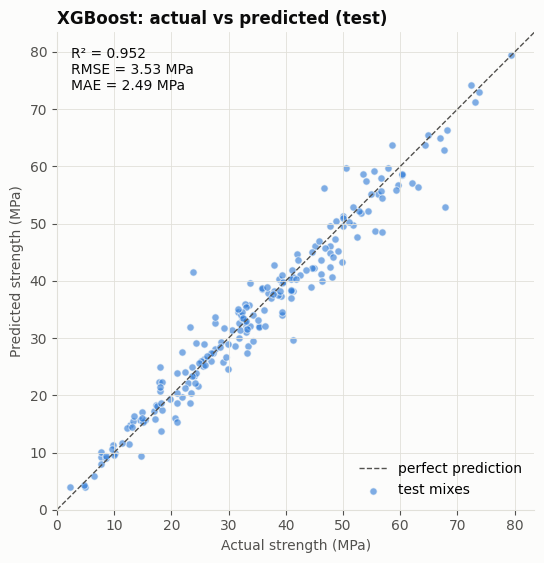

In [15]:
fig, ax = plt.subplots(figsize=(6.5, 6.2))
lims = [0, max(y_test.max(), pred_test.max()) * 1.05]
ax.plot(lims, lims, color=INK_2, linestyle='--', linewidth=1, label='perfect prediction')
ax.scatter(y_test, pred_test, s=28, color=COLOR, alpha=0.6, edgecolor=SURFACE, linewidth=0.8, label='test mixes')
ax.set_xlim(lims); ax.set_ylim(lims); ax.set_aspect('equal')
ax.set_xlabel('Actual strength (MPa)')
ax.set_ylabel('Predicted strength (MPa)')
ax.set_title(f'{best_name}: actual vs predicted (test)', loc='left')
ax.text(0.03, 0.97, f"R² = {final_metrics['test_R2']:.3f}\nRMSE = {final_metrics['test_RMSE']:.2f} MPa\n"
        f"MAE = {final_metrics['test_MAE']:.2f} MPa", transform=ax.transAxes, va='top', fontsize=10, color=INK)
ax.legend(frameon=False, loc='lower right')
plt.show()

### 7.2 Residuals (test set)

Residual = actual − predicted. A good model shows residuals scattered evenly around 0, with no funnel shape (variance changing with the prediction) and no curve (missed non-linearity).

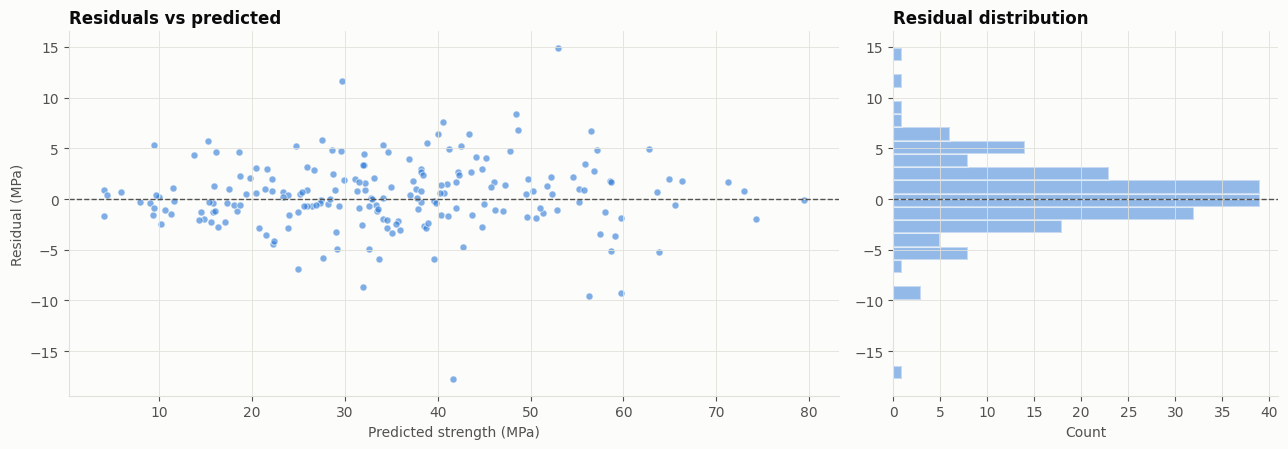

Residual mean: +0.33 MPa, std: 3.53 MPa
Share of test predictions within ±5 MPa: 87.6%
Largest absolute errors (MPa): [17.8, 14.9, 11.6, 9.6, 9.2]


In [16]:
resid = y_test - pred_test
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={'width_ratios': [2, 1]})
ax1.scatter(pred_test, resid, s=26, color=COLOR, alpha=0.6, edgecolor=SURFACE, linewidth=0.8)
ax1.axhline(0, color=INK_2, linestyle='--', linewidth=1)
ax1.set_xlabel('Predicted strength (MPa)')
ax1.set_ylabel('Residual (MPa)')
ax1.set_title('Residuals vs predicted', loc='left')

ax2.hist(resid, bins=25, color=COLOR, alpha=0.5, edgecolor=SURFACE, linewidth=1.5, orientation='horizontal')
ax2.axhline(0, color=INK_2, linestyle='--', linewidth=1)
ax2.set_xlabel('Count')
ax2.set_title('Residual distribution', loc='left')
ax2.sharey(ax1)
fig.tight_layout()
plt.show()

print(f'Residual mean: {resid.mean():+.2f} MPa, std: {resid.std():.2f} MPa')
print(f'Share of test predictions within ±5 MPa: {(resid.abs() <= 5).mean() * 100:.1f}%')
print(f'Largest absolute errors (MPa): {np.round(resid.abs().nlargest(5).values, 1).tolist()}')

### 7.3 Feature importance

**Permutation importance** on the test set: the drop in R² when one feature's values are randomly shuffled, repeated 20 times. It works for any model and is measured on unseen data. If the model also has built-in importances (from tree splits), they are shown alongside for comparison.

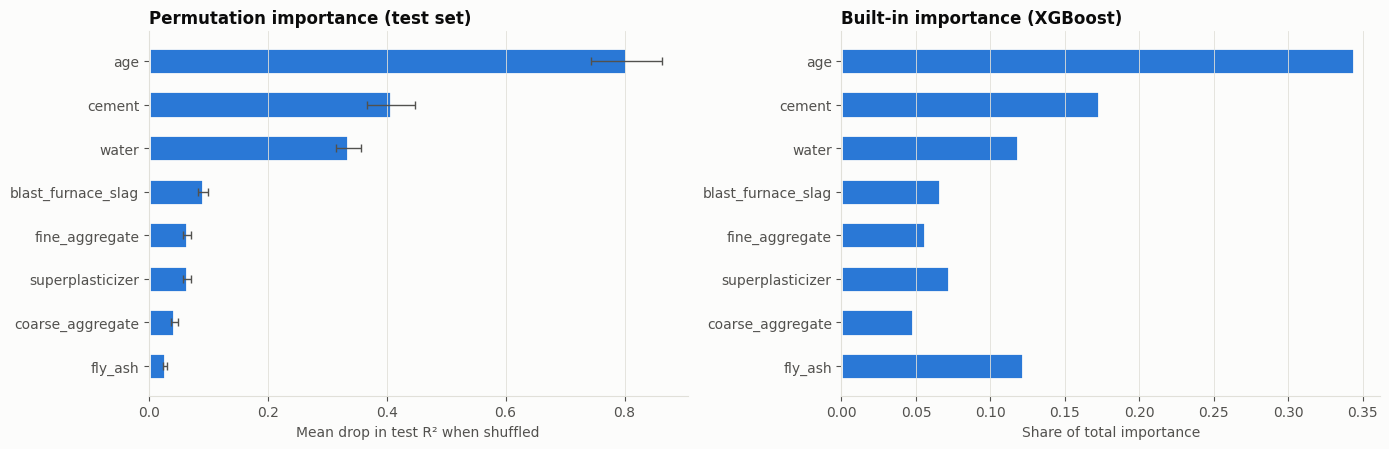

,perm_mean,perm_std,builtin
age,0.803,0.060,0.344
cement,0.407,0.041,0.173
water,0.335,0.021,0.119
blast_furnace_slag,0.091,0.009,0.066
fine_aggregate,0.064,0.007,0.056
superplasticizer,0.063,0.007,0.072
coarse_aggregate,0.043,0.006,0.048
fly_ash,0.027,0.004,0.122


In [17]:
perm = permutation_importance(best_pipe, X_test, y_test, scoring='r2', n_repeats=20,
                              random_state=SEED, n_jobs=-1)
importance = pd.DataFrame({'perm_mean': perm.importances_mean, 'perm_std': perm.importances_std},
                          index=FEATURES)
est = best_pipe.named_steps['model']
has_builtin = hasattr(est, 'feature_importances_')
if has_builtin:
    importance['builtin'] = est.feature_importances_
importance = importance.sort_values('perm_mean', ascending=False)

ncols = 2 if has_builtin else 1
fig, axes = plt.subplots(1, ncols, figsize=(7 * ncols, 4.6), squeeze=False)
t = importance.iloc[::-1]
ax = axes[0, 0]
ax.barh(t.index, t['perm_mean'], xerr=t['perm_std'], color=COLOR, height=0.6, edgecolor=SURFACE,
        linewidth=2, error_kw={'ecolor': INK_2, 'elinewidth': 1, 'capsize': 3})
ax.set_xlabel('Mean drop in test R² when shuffled')
ax.set_title('Permutation importance (test set)', loc='left')
ax.grid(axis='y', visible=False)
if has_builtin:
    ax = axes[0, 1]
    ax.barh(t.index, t['builtin'], color=COLOR, height=0.6, edgecolor=SURFACE, linewidth=2)
    ax.set_xlabel('Share of total importance')
    ax.set_title(f'Built-in importance ({best_name})', loc='left')
    ax.grid(axis='y', visible=False)
fig.tight_layout()
plt.show()
importance

**Reading the two charts:** when they disagree, trust permutation importance. Built-in tree importance counts how often and how usefully a feature is split on during training. It can rank a feature highly even if shuffling that feature barely changes predictions on unseen data. Zero-heavy features like `fly_ash` are a typical example.

---
## 8. Save

The saved bundle contains the **whole pipeline** (fitted scaler + model), so raw, unscaled mix values can be passed straight to `predict`. It also stores the feature order and the training ranges of each feature, so the app can flag inputs outside them as extrapolation.

In [18]:
bundle = {
    'pipeline': best_pipe,
    'model_name': best_name,
    'features': FEATURES,
    'target': TARGET,
    'target_unit': 'MPa',
    'feature_ranges': {c: {'min': float(X_train[c].min()), 'max': float(X_train[c].max())} for c in FEATURES},
    'best_params': {k.replace('model__', ''): v for k, v in searches[best_name].best_params_.items()},
    'metrics': {k: float(v) for k, v in final_metrics.items()},
    'split': {'test_size': 0.2, 'random_state': SEED, 'stratify': 'age_group x strength_quintile',
              'n_train': len(X_train), 'n_test': len(X_test)},
}
MODEL_PATH = MODEL_DIR / 'concrete_strength_model.joblib'
joblib.dump(bundle, MODEL_PATH)

comparison = cv_table.drop(columns='fold_R2').join(holdout[['train_R2', 'test_MAE', 'R2_gap']])
comparison.to_csv(MODEL_DIR / 'model_comparison.csv')
(MODEL_DIR / 'final_metrics.json').write_text(json.dumps(
    {k: v for k, v in bundle.items() if k != 'pipeline'}, indent=2, default=str))
print(f'Saved {MODEL_PATH}  ({MODEL_PATH.stat().st_size / 1024:.0f} KB)')

Saved models\concrete_strength_model.joblib  (866 KB)


### 8.1 Reload check

Reload the saved file and confirm it gives identical predictions, using an example mix taken from the test set.

In [19]:
loaded = joblib.load(MODEL_PATH)
assert np.allclose(loaded['pipeline'].predict(X_test), pred_test)

example = X_test.iloc[[0]]
display(example)
print(f"Predicted: {loaded['pipeline'].predict(example)[0]:.2f} MPa   Actual: {y_test.iloc[0]:.2f} MPa")

,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age
778,339.000,0.000,0.000,185.000,0.000,"1,060.000",754.000,28


Predicted: 34.47 MPa   Actual: 31.65 MPa


### 8.2 Summary of results

In [20]:
summary = comparison[['group', 'CV_R2_mean', 'CV_R2_std', 'test_R2', 'test_RMSE', 'test_MAE', 'R2_gap']].copy()
for name, s in searches.items():
    summary.loc[f'{name} (tuned)'] = ['tuned', s.best_score_, s.cv_results_['std_test_score'][s.best_index_],
                                      tuning.loc[name, 'test_R2_tuned'], tuning.loc[name, 'test_RMSE_tuned'],
                                      mean_absolute_error(y_test, s.predict(X_test)),
                                      r2_score(y_train, s.predict(X_train)) - tuning.loc[name, 'test_R2_tuned']]
summary = summary.sort_values('CV_R2_mean', ascending=False)
display(summary)

m = final_metrics
print(f'''
Best model : {best_name} (tuned)
CV R2      : {m['cv_R2']:.3f}  (5-fold, training set)
Test R2    : {m['test_R2']:.3f}
Test RMSE  : {m['test_RMSE']:.2f} MPa
Test MAE   : {m['test_MAE']:.2f} MPa
Top features (permutation): {', '.join(importance.index[:3])}
Saved to   : {MODEL_PATH}
''')

,group,CV_R2_mean,CV_R2_std,test_R2,test_RMSE,test_MAE,R2_gap
model,,,,,,,
XGBoost (tuned),tuned,0.925,0.018,0.952,3.534,2.495,0.038
XGBoost,advanced,0.912,0.018,0.939,4.009,2.673,0.058
Random Forest (tuned),tuned,0.896,0.024,0.918,4.634,3.348,0.067
Random Forest,advanced,0.895,0.024,0.915,4.714,3.431,0.069
Gradient Boosting,advanced,0.888,0.019,0.910,4.849,3.705,0.034
Decision Tree,advanced,0.818,0.028,0.843,6.411,4.343,0.154
KNN,advanced,0.681,0.023,0.701,8.846,6.966,0.109
Ridge,baseline,0.589,0.026,0.594,10.311,8.351,0.011
Linear Regression,baseline,0.589,0.027,0.595,10.304,8.338,0.010



Best model : XGBoost (tuned)
CV R2      : 0.925  (5-fold, training set)
Test R2    : 0.952
Test RMSE  : 3.53 MPa
Test MAE   : 2.49 MPa
Top features (permutation): age, cement, water
Saved to   : models\concrete_strength_model.joblib



**Notes**
- If test R² comes out above CV R², it means this particular 201-row test set happens to be slightly easier than the average CV fold. The CV score is the more conservative estimate of real performance.
- Predictions are a decision-support estimate for preliminary mix design. Laboratory compression testing is still required to validate a mix.
- The test score assumes mixes similar to the training data (see the caveat in 1.2). Use `feature_ranges` in the bundle to flag inputs outside the training range.